In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,classification_report, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

In [48]:
df_raw = pd.read_csv('sales.csv')
print('Original dataset shape:', df_raw.shape)
display(df_raw.head())
df_raw.info()

Original dataset shape: (7422, 9)


,Created,Product_ID,Source,Mobile,EMAIL,Sales_Agent,Location,Delivery_Mode,Status
0,14-11-2018 10:05,NaN,Website,984XXXXXXX,aXXXXXXX@gmail.com,Sales-Agent-11,NaN,Mode-5,Open
1,14-11-2018 09:22,NaN,Website,XXXXXXX,#VALUE!,Sales-Agent-10,NaN,Mode-5,Open
2,14-11-2018 09:21,NaN,Website,XXXXXXX,dXXXXXXX@yahoo.com,Sales-Agent-10,NaN,Mode-5,Open
3,14-11-2018 08:46,NaN,Website,XXXXXXX,wXXXXXXX@gmail.com,Sales-Agent-10,NaN,Mode-5,Open
4,14-11-2018 07:34,NaN,Website,XXXXXXX,cXXXXXXX@gmail.com,Sales-Agent-10,NaN,Mode-5,Open


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7422 entries, 0 to 7421
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Created        7422 non-null   object 
 1   Product_ID     7364 non-null   float64
 2   Source         7405 non-null   object 
 3   Mobile         5612 non-null   object 
 4   EMAIL          7422 non-null   object 
 5   Sales_Agent    7399 non-null   object 
 6   Location       7364 non-null   object 
 7   Delivery_Mode  7422 non-null   object 
 8   Status         7422 non-null   object 
dtypes: float64(1), object(8)
memory usage: 522.0+ KB


In [49]:
print('Columns:', df_raw.columns.tolist())
display(df_raw.isnull().sum().to_frame('Missing Values'))
print('Duplicate rows:', df_raw.duplicated().sum())
display(df_raw['Status'].astype('string').str.strip().str.upper().value_counts(dropna=False).to_frame('Count'))

Columns: ['Created', 'Product_ID', 'Source', 'Mobile', 'EMAIL', 'Sales_Agent', 'Location', 'Delivery_Mode', 'Status']


,Missing Values
Created,0
Product_ID,58
Source,17
Mobile,1810
EMAIL,0
Sales_Agent,23
Location,58
Delivery_Mode,0
Status,0


Duplicate rows: 2


,Count
Status,
JUNK LEAD,1536
NOT RESPONDING,1129
CONVERTED,852
JUST ENQUIRY,760
POTENTIAL,708
LONG TERM,646
IN PROGRESS POSITIVE,643
IN PROGRESS NEGATIVE,626
LOST,440


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


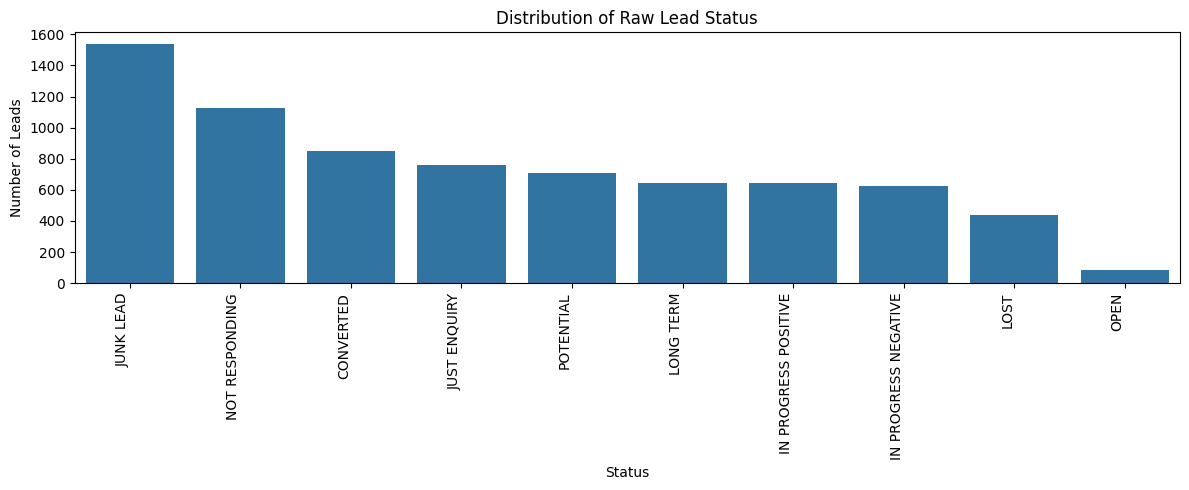

In [50]:
status_counts = (df_raw['Status'].astype('string').str.strip().str.upper().value_counts())
plt.figure(figsize=(12, 5))
sns.barplot(x=status_counts.index, y=status_counts.values)
plt.title('Distribution of Raw Lead Status')
plt.xlabel('Status')
plt.ylabel('Number of Leads')
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

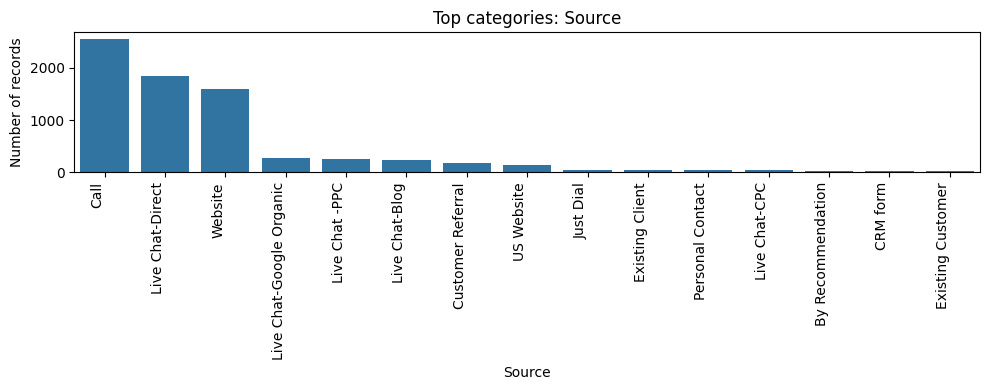

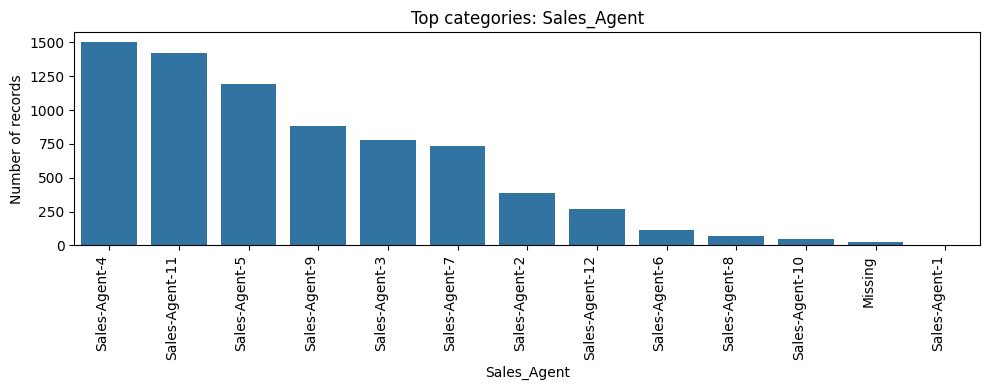

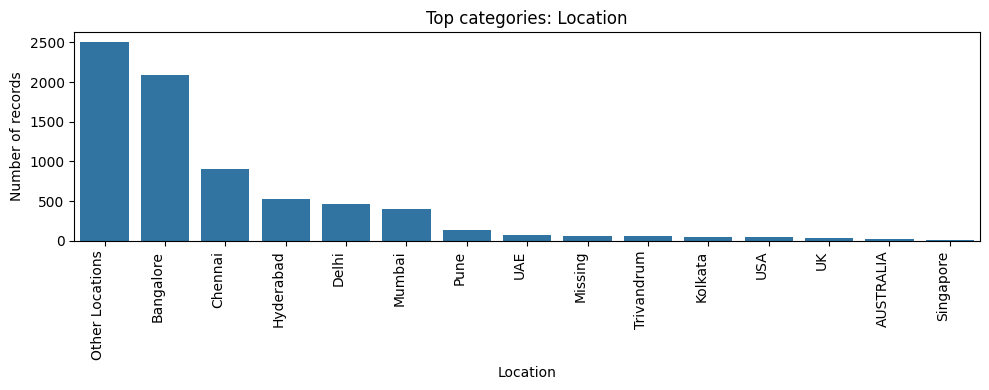

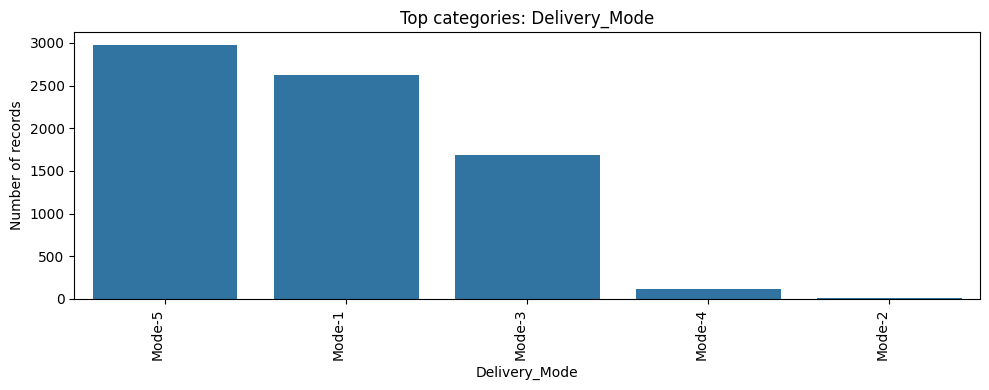

In [51]:
for col in ['Source', 'Sales_Agent', 'Location', 'Delivery_Mode']:
    if col in df_raw.columns:
        counts = df_raw[col].fillna('Missing').value_counts().head(15)
        plt.figure(figsize=(10, 4))
        sns.barplot(x=counts.index, y=counts.values)
        plt.title(f'Top categories: {col}')
        plt.xlabel(col)
        plt.ylabel('Number of records')
        plt.xticks(rotation=90, ha='right')
        plt.tight_layout()
        plt.show()

In [52]:
df = df_raw.copy()
df['Status'] = df['Status'].astype('string').str.strip().str.upper()
high_statuses = ['CONVERTED', 'POTENTIAL', 'IN PROGRESS POSITIVE','LONG TERM']
low_statuses = ['JUNK LEAD', 'LOST', 'IN PROGRESS NEGATIVE']
status_to_priority = {**{s: 'High Priority' for s in high_statuses},**{s: 'Low Priority' for s in low_statuses}}
df['Lead_Priority'] = df['Status'].map(status_to_priority)
print('Status counts:')
display(df['Status'].value_counts(dropna=False).to_frame('Count'))
print('Mapped priority counts:')
display(df['Lead_Priority'].value_counts(dropna=False).to_frame('Count'))
df = df.dropna(subset=['Lead_Priority']).copy()
df = df.drop_duplicates().reset_index(drop=True)
print('Modeling dataset shape:', df.shape)
display(df['Lead_Priority'].value_counts().to_frame('Count'))

Status counts:


,Count
Status,
JUNK LEAD,1536
NOT RESPONDING,1129
CONVERTED,852
JUST ENQUIRY,760
POTENTIAL,708
LONG TERM,646
IN PROGRESS POSITIVE,643
IN PROGRESS NEGATIVE,626
LOST,440


Mapped priority counts:


,Count
Lead_Priority,
High Priority,2849
Low Priority,2602
NaN,1971


Modeling dataset shape: (5451, 10)


,Count
Lead_Priority,
High Priority,2849
Low Priority,2602


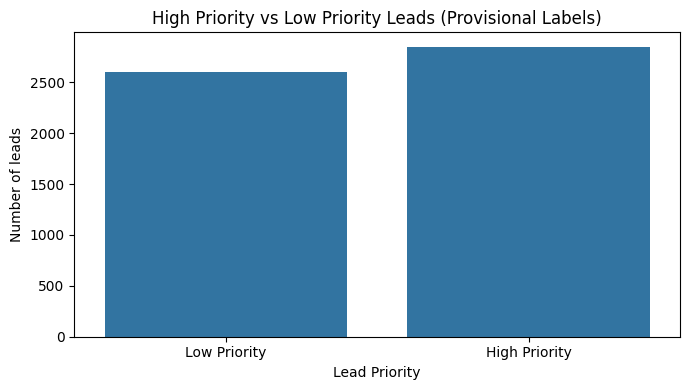

,proportion
Lead_Priority,
High Priority,52.27
Low Priority,47.73


In [53]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Lead_Priority', order=['Low Priority', 'High Priority'])
plt.title('High Priority vs Low Priority Leads (Provisional Labels)')
plt.xlabel('Lead Priority')
plt.ylabel('Number of leads')
plt.tight_layout()
plt.show()
display((df['Lead_Priority'].value_counts(normalize=True) * 100).round(2))

In [54]:
drop_cols = [c for c in ['Status', 'Mobile', 'EMAIL'] if c in df.columns]
df = df.drop(columns=drop_cols)
df['Created'] = pd.to_datetime(df['Created'],format='%d-%m-%Y %H:%M',errors='coerce')
df['Month'] = df['Created'].dt.month
df['Day'] = df['Created'].dt.day
df['Hour'] = df['Created'].dt.hour
df['Day_of_Week'] = df['Created'].dt.dayofweek
df = df.drop(columns=['Created'])
if 'Product_ID' in df.columns:
    df['Product_ID'] = df['Product_ID'].astype('string')
candidate_features = [c for c in df.columns if c != 'Lead_Priority']
constant_cols = [c for c in candidate_features if df[c].nunique(dropna=False) <= 1]
print('Constant columns removed:', constant_cols)
df = df.drop(columns=constant_cols)
print('Prepared shape:', df.shape)
display(df.head())
display(df.isnull().sum().to_frame('Missing Values'))

Constant columns removed: []
Prepared shape: (5451, 10)


,Product_ID,Source,Sales_Agent,Location,Delivery_Mode,Lead_Priority,Month,Day,Hour,Day_of_Week
0,9.0,Live Chat-Google Organic,Sales-Agent-3,Bangalore,Mode-1,High Priority,11,13,18,1
1,19.0,Call,Sales-Agent-4,Other Locations,Mode-5,High Priority,11,13,18,1
2,<NA>,Call,Sales-Agent-9,UAE,Mode-3,High Priority,11,13,17,1
3,18.0,Website,Sales-Agent-11,Trivandrum,Mode-1,High Priority,11,13,17,1
4,18.0,Call,Sales-Agent-7,Bangalore,Mode-1,High Priority,11,13,16,1


,Missing Values
Product_ID,4
Source,4
Sales_Agent,2
Location,2
Delivery_Mode,0
Lead_Priority,0
Month,0
Day,0
Hour,0
Day_of_Week,0


In [55]:
X = df.drop(columns=['Lead_Priority'])
y = df['Lead_Priority']
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20, random_state=42,stratify=y)
print('X shape:', X.shape)
print('Training shape:', X_train.shape)
print('Testing shape:', X_test.shape)
print('Training target counts:')
display(y_train.value_counts())
print('Testing target counts:')
display(y_test.value_counts())

X shape: (5451, 9)
Training shape: (4360, 9)
Testing shape: (1091, 9)
Training target counts:


,count
Lead_Priority,
High Priority,2279
Low Priority,2081


Testing target counts:


,count
Lead_Priority,
High Priority,570
Low Priority,521


In [56]:
categorical_features = X.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
numerical_features = X.select_dtypes(include=['number']).columns.tolist()
categorical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),('onehot', OneHotEncoder(handle_unknown='ignore'))])
numerical_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])
preprocessor = ColumnTransformer([('categorical', categorical_pipeline, categorical_features),('numerical', numerical_pipeline, numerical_features)])
print('Categorical features:', categorical_features)
print('Numerical features:', numerical_features)

Categorical features: ['Product_ID', 'Source', 'Sales_Agent', 'Location', 'Delivery_Mode']
Numerical features: ['Month', 'Day', 'Hour', 'Day_of_Week']


In [58]:
for col in X_train.columns:
    if isinstance(X_train[col].dtype, pd.StringDtype) or X_train[col].dtype == 'string' or X_train[col].isnull().any():
        X_train[col] = X_train[col].fillna(np.nan).astype(object)
        X_test[col] = X_test[col].fillna(np.nan).astype(object)

models = {'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced',random_state=42, n_jobs=-1),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'SVM': SVC(kernel='rbf', class_weight='balanced',probability=True, random_state=42)}
results = []
trained_models = {}
for model_name, estimator in models.items():
    pipe = Pipeline([('preprocessor', preprocessor),('classifier', estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append({'Model': model_name,'Accuracy': accuracy_score(y_test, pred),'Precision_High': precision_score(y_test, pred, pos_label='High Priority', zero_division=0),
        'Recall_High': recall_score(y_test, pred, pos_label='High Priority', zero_division=0),
        'F1_High': f1_score(y_test, pred, pos_label='High Priority', zero_division=0),
        'F1_Macro': f1_score(y_test, pred, average='macro', zero_division=0)})
    trained_models[model_name] = pipe
    print(model_name, 'completed')
results_df = pd.DataFrame(results).sort_values(by='F1_High', ascending=False).reset_index(drop=True)
display(results_df.round(4))

Logistic Regression completed
Decision Tree completed
Random Forest completed
KNN completed
SVM completed


,Model,Accuracy,Precision_High,Recall_High,F1_High,F1_Macro
0,SVM,0.7269,0.7337,0.7491,0.7413,0.7260
1,Random Forest,0.7159,0.7097,0.7719,0.7395,0.7135
2,Logistic Regression,0.7177,0.7290,0.7316,0.7303,0.7171
3,KNN,0.6929,0.7002,0.7211,0.7105,0.6918
4,Decision Tree,0.6838,0.6917,0.7123,0.7018,0.6826


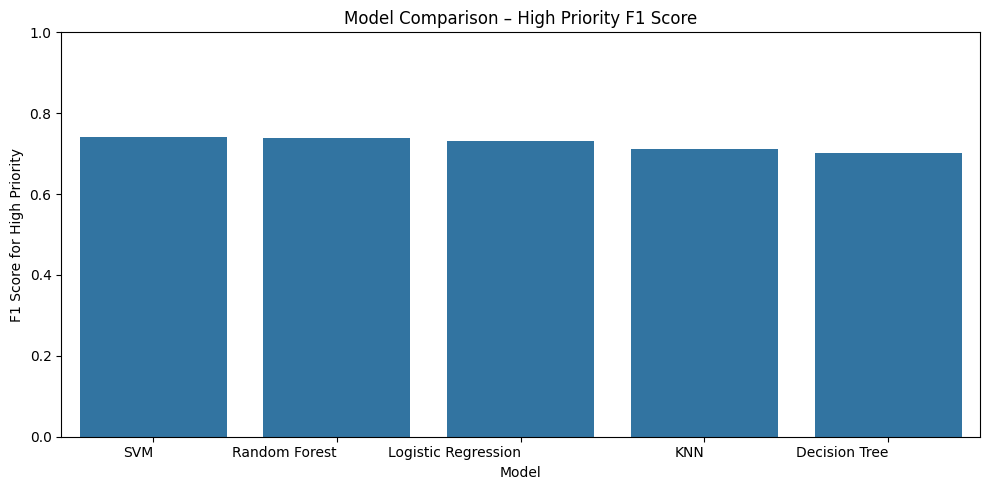

In [59]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x='Model', y='F1_High')
plt.title('Model Comparison – High Priority F1 Score')
plt.ylabel('F1 Score for High Priority')
plt.xticks(rotation=0, ha='right')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [60]:
best_model_name = results_df.loc[0, 'Model']
best_model = trained_models[best_model_name]
y_pred = best_model.predict(X_test)
print('Best model by High Priority F1:', best_model_name)
print(classification_report(y_test, y_pred,labels=['Low Priority', 'High Priority'],zero_division=0))

Best model by High Priority F1: SVM
               precision    recall  f1-score   support

 Low Priority       0.72      0.70      0.71       521
High Priority       0.73      0.75      0.74       570

     accuracy                           0.73      1091
    macro avg       0.73      0.73      0.73      1091
 weighted avg       0.73      0.73      0.73      1091



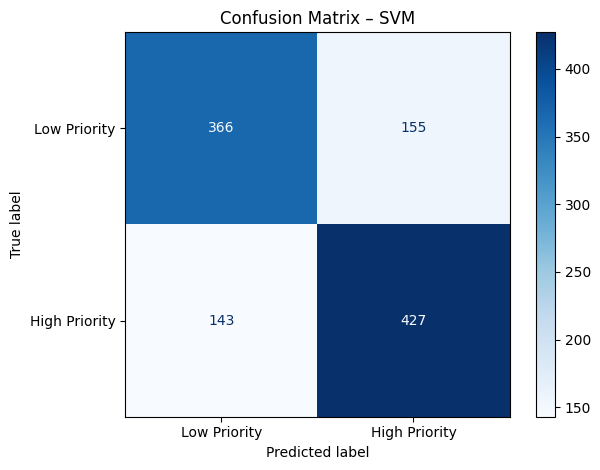

In [61]:
cm = confusion_matrix(y_test, y_pred,labels=['Low Priority', 'High Priority'])
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Low Priority', 'High Priority'])
disp.plot(cmap='Blues', values_format='d')
plt.title(f'Confusion Matrix – {best_model_name}')
plt.tight_layout()
plt.show()

In [62]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(best_model, X_train, y_train,cv=cv, scoring='f1_macro', n_jobs=-1)
print('5-fold macro F1 scores:', np.round(cv_scores, 4))
print('Mean CV macro F1:', round(cv_scores.mean(), 4))
print('Std CV macro F1:', round(cv_scores.std(), 4))

5-fold macro F1 scores: [0.7269 0.7333 0.7178 0.7049 0.71  ]
Mean CV macro F1: 0.7186
Std CV macro F1: 0.0105


,Feature,Importance_Mean,Importance_Std
0,Product_ID,0.084191,0.007676
2,Sales_Agent,0.055584,0.006960
5,Month,0.045701,0.007557
3,Location,0.033764,0.009525
4,Delivery_Mode,0.015867,0.005127
1,Source,0.012331,0.006225
6,Day,0.011127,0.005422
7,Hour,0.009834,0.004338
8,Day_of_Week,0.006100,0.005476


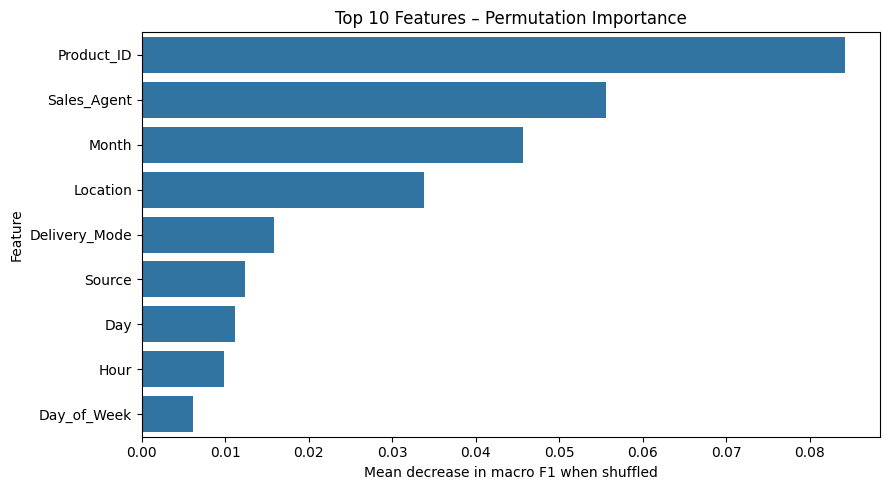

In [63]:
permutation = permutation_importance(best_model,X_test,y_test,scoring='f1_macro',n_repeats=10,random_state=42,n_jobs=-1)
feature_importance = pd.DataFrame({'Feature': X_test.columns,'Importance_Mean': permutation.importances_mean,'Importance_Std': permutation.importances_std}).sort_values(by='Importance_Mean',ascending=False)
display(feature_importance)
plt.figure(figsize=(9, 5))
sns.barplot(data=feature_importance.head(10),x='Importance_Mean',y='Feature')
plt.title('Top 10 Features – Permutation Importance')
plt.xlabel('Mean decrease in macro F1 when shuffled')
plt.tight_layout()
plt.show()

In [64]:
prediction_results = pd.DataFrame({'Actual_Category': y_test.reset_index(drop=True),'Predicted_Category': pd.Series(y_pred)})
display(prediction_results.head(20))
print('Actual category counts:')
display(prediction_results['Actual_Category'].value_counts())
print('Predicted category counts:')
display(prediction_results['Predicted_Category'].value_counts())

,Actual_Category,Predicted_Category
0,High Priority,High Priority
1,High Priority,High Priority
2,High Priority,High Priority
3,Low Priority,Low Priority
4,High Priority,High Priority
5,High Priority,High Priority
6,High Priority,High Priority
7,High Priority,Low Priority
8,High Priority,High Priority
9,Low Priority,Low Priority


Actual category counts:


,count
Actual_Category,
High Priority,570
Low Priority,521


Predicted category counts:


,count
Predicted_Category,
High Priority,582
Low Priority,509


In [70]:
y_pred = best_model.predict(X_test)
prediction_results = X_test.reset_index(drop=True).copy()
prediction_results['Actual_Category'] = (y_test.reset_index(drop=True))
prediction_results['Predicted_Category'] = y_pred
prediction_results['Prediction_Result'] = np.where(prediction_results['Actual_Category'] ==prediction_results['Predicted_Category'],'Correct','Incorrect')
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
display(prediction_results)

,Product_ID,Source,Sales_Agent,Location,Delivery_Mode,Month,Day,Hour,Day_of_Week,Actual_Category,Predicted_Category,Prediction_Result
0,19.0,Call,Sales-Agent-7,Bangalore,Mode-1,9,4,12,1,High Priority,High Priority,Correct
1,9.0,Live Chat-Direct,Sales-Agent-9,Chennai,Mode-1,10,15,10,0,High Priority,High Priority,Correct
2,25.0,Personal Contact,Sales-Agent-9,Bangalore,Mode-1,6,1,15,4,High Priority,High Priority,Correct
3,15.0,Call,Sales-Agent-5,Other Locations,Mode-5,6,28,12,3,Low Priority,Low Priority,Correct
4,18.0,Website,Sales-Agent-11,Hyderabad,Mode-1,6,5,16,1,High Priority,High Priority,Correct
5,9.0,Website,Sales-Agent-4,Other Locations,Mode-3,8,29,14,2,High Priority,High Priority,Correct
6,19.0,Website,Sales-Agent-9,Bangalore,Mode-3,6,19,14,1,High Priority,High Priority,Correct
7,10.0,Live Chat-Direct,Sales-Agent-4,Pune,Mode-5,6,10,13,6,High Priority,Low Priority,Incorrect
8,20.0,Live Chat-Direct,Sales-Agent-11,Other Locations,Mode-5,9,11,12,1,High Priority,High Priority,Correct
9,27.0,Website,Sales-Agent-5,Hyderabad,Mode-5,6,21,11,3,Low Priority,Low Priority,Correct


In [67]:
new_lead_values = {
    'Product_ID': '15',
    'Source': 'Website',
    'Sales_Agent': 'Sales-Agent-3',
    'Location': 'Bangalore',
    'Delivery_Mode': 'Mode-1',
    'Month': 11,
    'Day': 14,
    'Hour': 10,
    'Day_of_Week': 4}
new_lead = pd.DataFrame([new_lead_values])
new_lead = new_lead.reindex(columns=X.columns)
new_prediction = best_model.predict(new_lead)[0]
print('Predicted Lead Category:', new_prediction)
if hasattr(best_model, 'predict_proba'):
    probabilities = best_model.predict_proba(new_lead)[0]
    probability_output = pd.DataFrame({'Category': best_model.classes_,'Model Score': probabilities})
    display(probability_output)

Predicted Lead Category: High Priority


,Category,Model Score
0,High Priority,0.732113
1,Low Priority,0.267887


# ***Challenges***


1.   Missing values in dataset
2.   Duplicate records in dataset
3.   Different feature scales
4.   Class imbalance



# ***Solutions***

1.   Imputation to fix missing value
2.   Duplicate removal
3.   Standard Scaling to fix features
4.   Class-weighted models
5.   Compared five ML algorithms i.e. Logistic Regression, Decision Tree, Random Forest, K-Nearest Neighbors (KNN), and Support Vector Machine (SVM)



# ***Conclusion***
Sales Effectiveness Prediction project successfully demonstrates how machine learning can help classify sales leads into High Potential and Low Potential categories.Five machine learning algorithms were compared using evaluation metrics to identify the best-performing model. The final model can assist sales teams in prioritizing leads, improving follow-up strategies, and making data-driven decisions. However, predictions are based on historical data.